<a href="https://colab.research.google.com/github/LeonardooAlves/LSE-ST445/blob/main/Week%207/2_st445_week7_lab2_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ST445 Week 7 · Lab 2: exploratory data analysis, end to end

**About 2 hours · self-guided · applies the Week 7 lecture's EDA protocol**

In Lab 1 you learned **how** to draw charts. In this lab you use them to **understand a real dataset**. You will load the data, prepare it in a single documented cell, and then work through the lecture's **eight-step exploratory data analysis (EDA) protocol**. For every chart, the notebook gives:

1. **the questions** the chart can answer, written before the chart is drawn;
2. **how the code works**, line by line where it introduces something new;
3. **the best-practice principles** the chart applies, from the lecture;
4. **the insight** the chart supports, stated as a **claim**, its **evidence** and its **limits** (lecture: stating an insight).

At the end, you repeat the whole process on a different dataset.

| Section | What happens |
|---|---|
| 0 | The dataset and its documentation |
| 1 | Set-up, and loading the data with a record of where it came from |
| 2 | **Preprocessing in one cell**: making the data ready for analysis |
| 3 | **The eight-step EDA protocol**, with 11 charts |
| 4 | A summary table of the insights |
| 5 | **Exercise:** the same process on the UCI Air Quality dataset |

**Before you start:** choose **File → Save a copy in Drive**, so that your changes are saved.

### Documentation you will use

| Library | Guide | Reference for every function |
|---|---|---|
| pandas | [User guide](https://pandas.pydata.org/docs/user_guide/index.html) | [API reference](https://pandas.pydata.org/docs/reference/index.html) |
| Matplotlib | [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html) | [API reference](https://matplotlib.org/stable/api/index.html) |
| seaborn | [Overview of plotting functions](https://seaborn.pydata.org/tutorial/function_overview.html) | [API reference](https://seaborn.pydata.org/api.html) |

Each function is linked to its reference page where it is first explained.

---
## 0. The dataset: Capital Bikeshare, Washington DC, 2011–2012

The **Bike Sharing** dataset records how many bikes were hired on each day from Capital Bikeshare, the public bike-hire scheme in Washington DC, during 2011 and 2012, together with that day's weather and calendar information. It is a good dataset for practising EDA because it contains clear structure (growth over time, a seasonal cycle, effects of the weather, two different kinds of user) and a few genuine anomalies.

* **Source:** UCI Machine Learning Repository, dataset 275: [archive.ics.uci.edu/dataset/275/bike+sharing+dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)
* **Creators:** Hadi Fanaee-T and João Gama (2013), from Capital Bikeshare's public trip records and published weather records.
* **Licence:** [Creative Commons Attribution 4.0 (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/): the data may be reused, provided the source is credited.
* **Citation:** Fanaee-T, H. and Gama, J. (2014), "Event labeling combining ensemble detectors and background knowledge", *Progress in Artificial Intelligence*, 2(2), 113–127.

The download is a zip file containing two data files: `hour.csv`, with one row per hour, and **`day.csv`**, with one row per day, which we use.

### Data dictionary for `day.csv`, as published

A **data dictionary** describes each column: its meaning, its units and its codes. Read it before analysing anything (lecture, step 1).

| Column | Meaning |
|---|---|
| `instant` | row number |
| `dteday` | the date |
| `season` | a code: 1 = winter, 2 = spring, 3 = summer, 4 = autumn |
| `yr` | a code: 0 = 2011, 1 = 2012 |
| `mnth` | the month, 1 to 12 |
| `holiday` | 1 if the day is a public holiday, otherwise 0 |
| `weekday` | the day of the week, 0 = Sunday to 6 = Saturday |
| `workingday` | 1 if the day is neither a weekend nor a holiday, otherwise 0 |
| `weathersit` | a code: 1 = clear or partly cloudy; 2 = mist or cloud; 3 = light rain or light snow; 4 = heavy rain, snow or fog |
| `temp` | the temperature in °C, **divided by 41**, so between 0 and 1 |
| `atemp` | the "feels like" temperature in °C, **divided by 50** |
| `hum` | the relative humidity in %, **divided by 100** |
| `windspeed` | the wind speed in km/h, **divided by 67** |
| `casual` | hires by casual users (people without a membership) |
| `registered` | hires by registered users (members) |
| `cnt` | total hires, equal to `casual + registered` |

Two things in this table need preparing before the charts can be read: the weather values are **normalised** (divided by a maximum, so they lie between 0 and 1, rather than being in real units), and the categories are stored as **numeric codes** (1, 2, 3, ...) rather than names.

---
## 1. Set-up and loading

### Imports and style

The first cell imports the libraries and sets a style for every chart, as in Lab 1. Three modules come from Python's standard library and are needed for downloading:

* [`urllib.request`](https://docs.python.org/3/library/urllib.request.html) downloads a file from a web address;
* [`zipfile`](https://docs.python.org/3/library/zipfile.html) opens a zip archive;
* [`hashlib`](https://docs.python.org/3/library/hashlib.html) computes a checksum (below).

In [4]:
# 🟢 Imports, a colour-blind-safe palette and default settings
import hashlib                       # checksums, to record exactly which file was used
import io                            # treats downloaded bytes as a file in memory
import urllib.request                # downloads files from the web
import zipfile                       # opens zip archives
from datetime import datetime, timezone
from pathlib import Path             # file paths that work on any operating system

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates    # controls how dates appear on an axis
import seaborn as sns

# The Okabe-Ito colour-blind-safe palette (Okabe and Ito, 2008)
OKABE_ITO = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#009E73",  # bluish green
    "#CC79A7",  # reddish purple
    "#56B4E9",  # sky blue
    "#D55E00",  # vermilion
    "#F0E442",  # yellow
    "#000000",  # black
]
GREY = "#B0B7BF"                     # a neutral grey for context and background elements. Okabe Grey: "#999999"

sns.set_theme(style="ticks",         # white background with tick marks on the axes
              palette=OKABE_ITO)     # seaborn's default colours for this notebook
plt.rcParams.update({
    "figure.dpi": 110,               # resolution on screen, in dots (pixels) per inch
    "axes.spines.top": False,        # remove the top border line of every plot
    "axes.spines.right": False,      # remove the right border line of every plot
})

### Download the data, and record where they came from

The next cell downloads the zip file from the UCI repository, extracts `day.csv`, and saves it in the notebook's working folder. It downloads only if the file is not already there, so re-running the cell does not download again.

It then creates a **provenance record** (Week 2): a small dictionary saying where the data came from, when they were retrieved, under which licence, and the file's **SHA-256 checksum**. A checksum is a long code calculated from every byte of the file; any change to the file, however small, gives a different checksum. Recording it lets anyone confirm later that they are analysing exactly the same file.

**If the download fails** (for example, because there is no internet connection), download the zip file from the UCI page linked in section 0, extract `day.csv`, upload it with the **Files** panel on the left of Colab, and run the cell again.

In [5]:
# 🟢 Download the file once, record its provenance, then read it into a DataFrame
URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
DAY_FILE = Path("day.csv")

if not DAY_FILE.exists():                                   # download only if the file is not already here
    with urllib.request.urlopen(URL, timeout=60) as response:
        zipped = response.read()                            # the zip file, as bytes
    with zipfile.ZipFile(io.BytesIO(zipped)) as archive:    # open the bytes as a zip archive
        DAY_FILE.write_bytes(archive.read("day.csv"))       # extract day.csv and save it

provenance = {
    "source": URL,
    "file": str(DAY_FILE),
    "retrieved_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),   # the time, in UTC
    "sha256": hashlib.sha256(DAY_FILE.read_bytes()).hexdigest(),               # the checksum
    "licence": "CC BY 4.0",
}
print(provenance)

raw = pd.read_csv(DAY_FILE)        # read the CSV file into a DataFrame
raw.head()                         # show the first five rows

{'source': 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip', 'file': 'day.csv', 'retrieved_at': '2026-11-12T02:16:53+00:00', 'sha256': 'a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be', 'licence': 'CC BY 4.0'}


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**What you should see:** the provenance record, then the first five rows of the data: dates starting on 2011-01-01, numeric codes in `season`, `weathersit` and `weekday`, and decimals between 0 and 1 in the weather columns.

We keep the DataFrame `raw` exactly as read from the file, and build a cleaned copy from it in the next section: as in Week 4, **raw data are never changed**, so the cleaning can always be repeated or checked. Link: [`pd.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html).

---
## 2. Preprocessing, in one cell

**Preprocessing** means turning the data as published into data that are ready for analysis: correct types, readable names, real units, and checks that the data are what the documentation says. Everything is done in **one cell**, so that the whole preparation can be read, reviewed and re-run as a single unit. Each step has a comment saying **what** it does and **why**.

Four pandas tools appear here for the first time:

* [`map`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html) replaces each value using a dictionary: here, each numeric code with its name.
* [`pd.Categorical`](https://pandas.pydata.org/docs/reference/api/pandas.Categorical.html) creates a **categorical** column: one that can take only a fixed list of values (its **categories**). With `ordered=True`, the categories have a meaningful order, such as winter → spring → summer → autumn, which pandas and seaborn then use in every table and chart instead of alphabetical order.
* [`.dt.day_name()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.day_name.html) gives the name of the day of the week for each date.
* **`assert condition, "message"`** stops the program with the message if the condition is false ([Python: the assert statement](https://docs.python.org/3/reference/simple_stmts.html#the-assert-statement)). The checks at the end of the cell **fail loudly**: if the data are not as expected, the notebook stops rather than drawing a misleading chart (Week 4: validation as code).

In [6]:
# 🟢 Prepare the data for EDA: one documented cell that can be re-run at any time
bikes = raw.copy()                       # work on a copy, so that raw stays exactly as downloaded

# 1. Drop the row number: it carries no information, and could be mistaken for a variable
bikes = bikes.drop(columns="instant")

# 2. Give the columns readable names, so they can serve directly as chart labels
bikes = bikes.rename(columns={
    "dteday": "date",
    "yr": "year",
    "mnth": "month",
    "weathersit": "weather",
    "hum": "humidity",
    "cnt": "total",
    "atemp": "feels_like",
})

# 3. Convert the date from text to a datetime, so that time-series tools work
#    (format="%Y-%m-%d" states the format exactly, instead of letting pandas guess it)
bikes["date"] = pd.to_datetime(bikes["date"], format="%Y-%m-%d")

# 4. Replace the numeric codes with named, ordered categories, so that charts show names
#    in a meaningful order (winter to autumn; Monday to Sunday) rather than numbers
bikes["season"] = pd.Categorical(
    bikes["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Autumn"}),
    categories=["Winter", "Spring", "Summer", "Autumn"],
    ordered=True,
)
bikes["weather"] = pd.Categorical(
    bikes["weather"].map({1: "Clear", 2: "Mist or cloud", 3: "Light rain or snow", 4: "Heavy rain or snow"}),
    categories=["Clear", "Mist or cloud", "Light rain or snow", "Heavy rain or snow"],
    ordered=True,
)
# The day of the week is rebuilt from the date itself, so it can never disagree with the date
bikes["weekday"] = pd.Categorical(
    bikes["date"].dt.day_name().str[:3],          # "Monday" -> "Mon", and so on
    categories=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    ordered=True,
)
bikes["year"] = bikes["year"].map({0: 2011, 1: 2012})      # the real year, instead of a 0/1 code

# 5. Store the two calendar indicators as True/False, which reads more clearly than 1/0
bikes["holiday"] = bikes["holiday"].astype(bool)
bikes["workingday"] = bikes["workingday"].astype(bool)

# 6. Undo the normalisation, using the divisors in the data dictionary, so weather is in real units
bikes["temp_c"] = (bikes["temp"] * 41).round(1)             # degrees Celsius
bikes["feels_like_c"] = (bikes["feels_like"] * 50).round(1) # degrees Celsius
bikes["humidity_pct"] = (bikes["humidity"] * 100).round(0)  # per cent
bikes["wind_kmh"] = (bikes["windspeed"] * 67).round(1)      # kilometres per hour
bikes = bikes.drop(columns=["temp", "feels_like", "humidity", "windspeed"])   # remove the normalised versions

# 7. Add a derived variable: the share of each day's hires made by casual users
bikes["casual_share"] = (bikes["casual"] / bikes["total"]).round(3)

# 8. Sort by date and renumber the rows from 0: a time series must be in time order
bikes = bikes.sort_values("date").reset_index(drop=True)

# 9. Validation: stop with a message if the data are not what the documentation promises
assert len(bikes) == 731, f"expected 731 days, found {len(bikes)}"
assert bikes["date"].is_unique, "a date appears more than once"
assert (bikes["date"].diff().dropna() == pd.Timedelta(days=1)).all(), "a day is missing from the series"
assert (bikes["casual"] + bikes["registered"] == bikes["total"]).all(), "casual + registered does not equal total"
assert bikes[["season", "weather", "weekday"]].notna().all().all(), "a code was not converted to a name"
assert bikes["temp_c"].between(-15, 45).all(), "a temperature outside a plausible range for Washington DC"

print("Ready for EDA:", bikes.shape)
bikes.head()

Ready for EDA: (731, 16)


,date,season,year,month,holiday,weekday,workingday,weather,casual,registered,total,temp_c,feels_like_c,humidity_pct,wind_kmh,casual_share
0,2011-01-01,Winter,2011,1,False,Sat,False,Mist or cloud,331,654,985,14.1,18.2,81.0,10.7,0.336
1,2011-01-02,Winter,2011,1,False,Sun,False,Mist or cloud,131,670,801,14.9,17.7,70.0,16.7,0.164
2,2011-01-03,Winter,2011,1,False,Mon,True,Clear,120,1229,1349,8.1,9.5,44.0,16.6,0.089
3,2011-01-04,Winter,2011,1,False,Tue,True,Clear,108,1454,1562,8.2,10.6,59.0,10.7,0.069
4,2011-01-05,Winter,2011,1,False,Wed,True,Clear,82,1518,1600,9.3,11.5,44.0,12.5,0.051


**What you should see:** `Ready for EDA: (731, 17)` (731 rows and 17 columns), then a table with readable column names, real dates, names instead of codes, and the weather in °C, % and km/h. If any check had failed, the cell would have stopped and printed the check's message.

**Reading two of the checks:**

* `bikes["date"].diff()` computes the difference between each date and the one before it. In a complete daily series, every difference equals one day, so the check confirms that no day is missing.
* `.notna().all().all()` is true only if there is **no** missing value anywhere in the three category columns: a missing value there would mean a code that was not in the mapping dictionary.

**Two decisions worth recording** (the kind of decision that belongs in a Week 4 decision log):

* **The day of the week was rebuilt from the date**, rather than converted from the published `weekday` code, so the two can never disagree.
* **No rows were removed.** Unusual days are examined in step 7 of the protocol; removing them now, before looking at them, would hide information.

---
## 3. The EDA protocol

The eight steps from the lecture, in order. Each step prepares the next: for example, knowing what one row represents (step 1) is needed to interpret every count that follows.

| Step | Question |
|---|---|
| 1 | **Shape and types:** what does one row represent, and what type is each column? |
| 2 | **Univariate distributions:** what does each variable look like on its own? |
| 3 | **Missingness:** what is missing, where, and why? |
| 4 | **Relationships:** how do pairs of variables vary together? |
| 5 | **Groups and subgroups:** does a pattern hold within each group, or only overall? |
| 6 | **Time structure:** is there a trend, a seasonal cycle, or a sudden change? |
| 7 | **Outliers and anomalies:** is each unusual value impossible, implausible or genuinely extreme? |
| 8 | **Data quality:** what did the charts reveal that the cleaning should now address? |

### Step 1: shape and types

Three pandas tools give the first overview of any dataset:

* **`.shape`** gives the number of rows and columns;
* **`.dtypes`** gives each column's **data type**: for example `int64` (whole numbers), `float64` (decimals), `datetime64` (dates and times), `bool` (True or False) and `category` (one of a fixed list of values);
* [`.describe()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html) gives summary statistics for each numeric column: the count of values, the mean, the standard deviation (`std`, a measure of spread), the minimum, the quartiles (25%, 50% and 75%) and the maximum.

In [7]:
# 🟢 Size, types and summary statistics
print(bikes.shape)
print()
print(bikes.dtypes)
bikes.describe().round(1)            # .round(1): show one decimal place

(731, 16)

date            datetime64[ns]
season                category
year                     int64
month                    int64
holiday                   bool
weekday               category
workingday                bool
weather               category
casual                   int64
registered               int64
total                    int64
temp_c                 float64
feels_like_c           float64
humidity_pct           float64
wind_kmh               float64
casual_share           float64
dtype: object


,date,year,month,casual,registered,total,temp_c,feels_like_c,humidity_pct,wind_kmh,casual_share
count,731,731.0,731.0,731.0,731.0,731.0,731.0,731.0,731.0,731.0,731.0
mean,2012-01-01 00:00:00,2011.5,6.5,848.2,3656.2,4504.3,20.3,23.7,62.8,12.8,0.2
min,2011-01-01 00:00:00,2011.0,1.0,2.0,20.0,22.0,2.4,4.0,0.0,1.5,0.0
25%,2011-07-02 12:00:00,2011.0,4.0,315.5,2497.0,3152.0,13.8,16.9,52.0,9.0,0.1
50%,2012-01-01 00:00:00,2012.0,7.0,713.0,3662.0,4548.0,20.4,24.3,63.0,12.1,0.1
75%,2012-07-01 12:00:00,2012.0,10.0,1096.0,4776.5,5956.0,26.9,30.4,73.0,15.6,0.2
max,2012-12-31 00:00:00,2012.0,12.0,3410.0,6946.0,8714.0,35.3,42.0,97.0,34.0,0.5
std,NaN,0.5,3.5,686.6,1560.3,1937.2,7.5,8.1,14.3,5.2,0.1


**What one row represents:** **one day** in Washington DC, with that day's number of bike hires, its weather and its calendar information. There are 731 days: all of 2011 (365 days) and all of 2012, a leap year (366 days).

**The types:** `date` is a datetime; `season`, `weather` and `weekday` are ordered categories; `holiday` and `workingday` are True or False; the hire counts are whole numbers; the weather values are decimals. Every later step depends on this: a count of rows is a count of **days**.

**What the summary already shows:** daily hires (`total`) range from a few dozen to more than 8,000, with a mean of about 4,500. A minimum of a few dozen hires is suspiciously low for a scheme covering a whole city: a question to investigate in step 7.

### Step 2: univariate distributions

A **univariate** distribution describes one variable on its own: its typical value (centre), how widely it varies (spread), whether it is symmetric or **skewed** (with a longer tail on one side), whether it has one peak or several, and whether any values look out of place.

#### Chart 2.1: daily hires

**Questions this chart can answer**

* What is the number of hires on a typical day, and how much does it vary from day to day?
* Is the distribution symmetric, skewed, or made of more than one group?
* Are there days that look out of place?

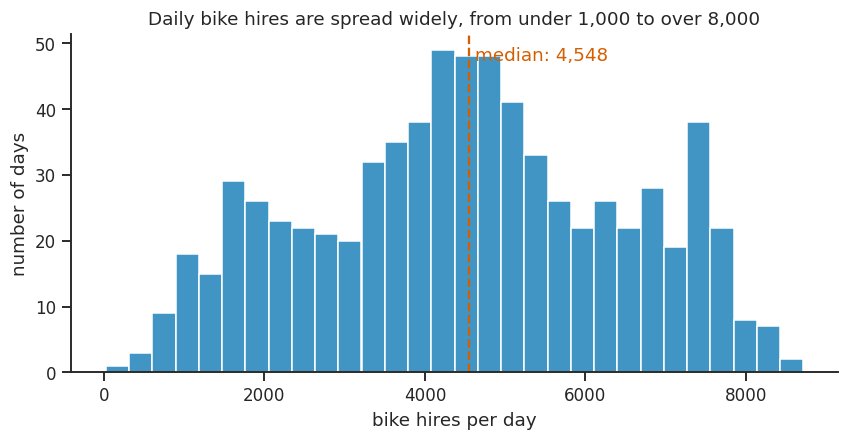

count     731.0
mean     4504.0
std      1937.0
min        22.0
25%      3152.0
50%      4548.0
75%      5956.0
max      8714.0
Name: total, dtype: float64


In [8]:
# 🟢 A histogram of daily hires, with the median marked
median_total = bikes["total"].median()          # the middle value: half the days had more hires

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=bikes, x="total",
             bins=30,                           # the number of bars
             color=OKABE_ITO[0],
             ax=ax)
ax.axvline(median_total,                        # a vertical reference line at the median
           color=OKABE_ITO[5],
           linestyle="--",                      # dashed
           linewidth=1.5)
ax.text(median_total + 80,                      # just to the right of the line
        ax.get_ylim()[1] * 0.92,                # near the top: 92% of the y-axis height
        f"median: {median_total:,.0f}",         # :,.0f = a comma for thousands, no decimals
        color=OKABE_ITO[5])
ax.set(title="Daily bike hires are spread widely, from under 1,000 to over 8,000",
       xlabel="bike hires per day", ylabel="number of days")
plt.show()

print(bikes["total"].describe().round(0))

**How the code works.** [`sns.histplot`](https://seaborn.pydata.org/generated/seaborn.histplot.html) counts how many days fall into each of 30 equal-width ranges of `total`. [`ax.axvline`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvline.html) draws a vertical line across the whole plot. `ax.get_ylim()` returns the lowest and highest values of the y-axis, so `ax.get_ylim()[1] * 0.92` places the label at 92% of the plot's height, whatever the data.

**Best-practice principles applied**

* **The chart was chosen for the question:** the distribution of one numeric variable, so a histogram (lecture: choosing a chart from the question).
* **The title states the finding**, rather than only naming the variable, and **both axes are labelled with what they measure** (Appendix B: annotation and labelling).
* **A reference line** (the median) gives the reader something to compare against, in a distinct colour and labelled directly on the chart rather than in a legend.
* **The bin width was tested:** re-run the cell with `bins=15` and `bins=60`. The broad, flat shape remains, so it is not an artefact of the bin width (lecture: pattern or artefact?).

**Insight**

| | |
|---|---|
| **Claim** (what we found) | On a typical day there were about 4,500 hires, but days varied enormously: the middle half of days had roughly between 3,000 and 6,000 hires, and the distribution is broad and fairly flat rather than concentrated around one peak. |
| **Evidence** (what shows it) | The histogram, and the quartiles printed below it (the 25% and 75% values bound the middle half of days). |
| **Limits** (what could make it wrong, or narrower) | A wide, flat distribution often means that the data mix different conditions, such as seasons, years or weather. The histogram cannot say which: steps 5 and 6 test that. The data cover two years of a growing scheme, so a 'typical day' is a moving target. |

#### Chart 2.2: the weather variables, as small multiples

**Questions this chart can answer**

* What range of temperature, humidity and wind did the city experience?
* Are any values impossible or suspicious?

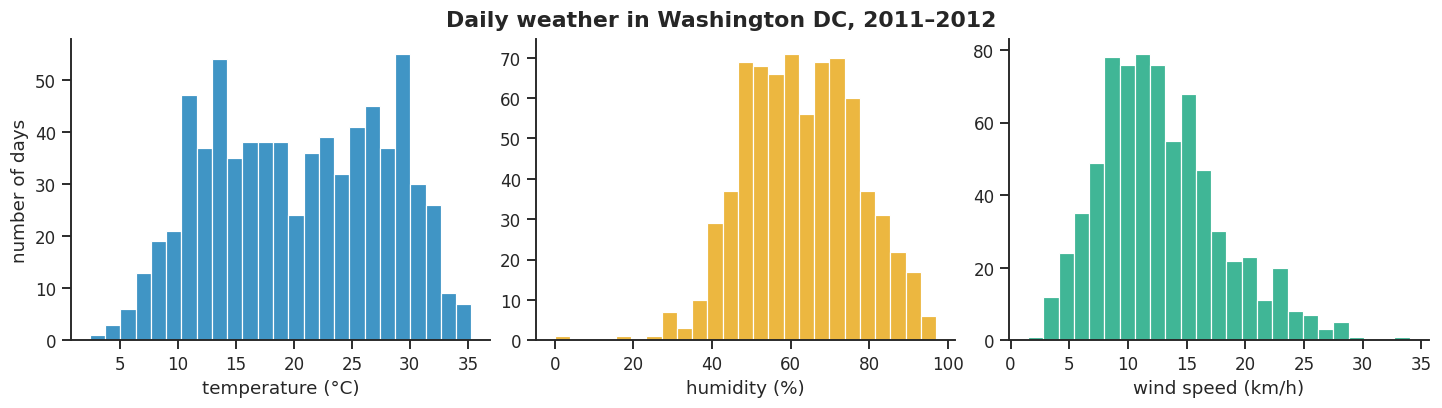

the three lowest humidity values: [0.0, 19.0, 25.0]


In [9]:
# 🟢 Three weather variables, one plot each
weather_vars = [                                 # (column name, axis label with its unit)
    ("temp_c", "temperature (°C)"),
    ("humidity_pct", "humidity (%)"),
    ("wind_kmh", "wind speed (km/h)"),
]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6),
                        layout="constrained")    # space the plots so that no labels overlap
for i, (column, label) in enumerate(weather_vars):
    sns.histplot(data=bikes, x=column, bins=25, color=OKABE_ITO[i], ax=axs[i])
    axs[i].set(xlabel=label,
               ylabel="number of days" if i == 0 else "")   # a y-axis label on the first plot only
fig.suptitle("Daily weather in Washington DC, 2011–2012", fontweight="bold")
plt.show()

print("the three lowest humidity values:", sorted(bikes["humidity_pct"])[:3])

**How the code works.** The list `weather_vars` holds pairs of (column, label). The loop draws one histogram per pair on its own axes, `axs[i]`. The expression `"number of days" if i == 0 else ""` gives the first plot a y-axis label and leaves the other two blank, because the label would only repeat.

**Best-practice principles applied**

* **Small multiples:** the same chart type for each variable, side by side, so the three can be compared without a legend (lecture: layout and small multiples).
* **Real units on every axis.** This was only possible because preprocessing undid the normalisation (Appendix B: the plotted quantity and its units are defined).
* **One colour per variable**, from a colour-blind-safe palette. Colour here only identifies the plot; it encodes no value.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Temperatures cover a full temperate year, from about 2 °C to about 35 °C, spread across the whole range rather than around one peak. Humidity is mostly between 40% and 90%. Wind is usually light, with a long tail of windier days (right-skewed). |
| **Evidence** (what shows it) | The three histograms, and the printout of the lowest humidity values. |
| **Limits** (what could make it wrong, or narrower) | **One humidity value is 0%.** Outdoor air in Washington is never completely dry, so this is almost certainly a recording error; it is examined in step 7. All three values are **daily averages**, which hide the weather during the particular hours when people ride. |

#### Chart 2.3: how often each kind of weather occurred

**Questions this chart can answer**

* How common were rainy or snowy days?
* Are any weather categories too small to compare reliably?

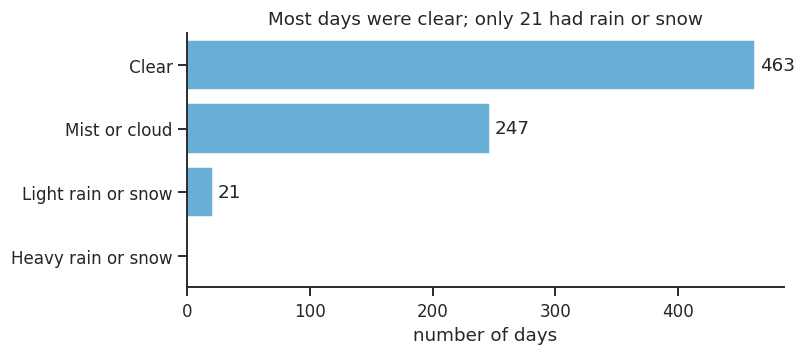

weather
Clear                 463
Mist or cloud         247
Light rain or snow     21
Heavy rain or snow      0
Name: count, dtype: int64


In [10]:
# 🟢 The number of days in each weather category
fig, ax = plt.subplots(figsize=(7, 3))
sns.countplot(data=bikes, y="weather",          # y=: horizontal bars, one per category
              color=OKABE_ITO[4],
              ax=ax)
for container in ax.containers:                 # each group of bars drawn by seaborn
    ax.bar_label(container, padding=3)          # write each bar's value at its end, 3 points away
ax.set(title="Most days were clear; only 21 had rain or snow",
       xlabel="number of days", ylabel="")
plt.show()

print(bikes["weather"].value_counts(sort=False))   # sort=False: keep the categories' own order

**How the code works.** [`sns.countplot`](https://seaborn.pydata.org/generated/seaborn.countplot.html) counts the rows in each category of `weather`. Because `weather` is an ordered category, the bars follow its order (clear to heavy) rather than their size. [`ax.bar_label`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar_label.html) writes the value of each bar at its end; `ax.containers` holds the groups of bars that seaborn drew.

**Best-practice principles applied**

* **Horizontal bars** leave room for the long category names, and **start at zero**, because each bar's length represents its count (lecture: baselines).
* **The values are written on the bars**, so the reader does not need gridlines or the axis to read them (lecture: data-ink and decluttering).
* **The empty category is shown, not hidden:** 'Heavy rain or snow' has no days at all, which is information in itself.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | About 63% of days were clear and 34% misty or cloudy. Only 21 days (about 3%) had light rain or snow, and none had heavy rain or snow. |
| **Evidence** (what shows it) | The labels on the bars, and the printed counts. |
| **Limits** (what could make it wrong, or narrower) | **Small groups:** any comparison involving the 21 rain or snow days rests on few observations, so it is imprecise; its sample size should be shown wherever it is used (Appendix B: uncertainty). Each category is a single summary of a day whose weather may have changed. |

### Step 3: missingness

There are two kinds of missing data to look for:

1. **values marked as missing**, which pandas shows as `NaN` and counts with [`.isna()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html);
2. **data missing without being marked**: a code that stands for "unknown" (such as the −200 in Week 4, or 0 in a column where 0 is impossible), or a whole **row** that is absent, such as a day missing from a time series.

The second kind cannot be found with `.isna()`; it needs a specific check.

In [11]:
# 🟢 Marked missing values, then two checks for unmarked ones
missing = bikes.isna().sum()                    # the number of missing values in each column
print("columns with missing values:", missing[missing > 0].to_dict() if missing.any() else "none")

expected_days = pd.date_range("2011-01-01", "2012-12-31", freq="D")    # every day in the two years
absent = expected_days.difference(bikes["date"])                      # days expected but not present
print("days absent from the series:", len(absent))

print("days per year:", bikes.groupby("year").size().to_dict())
print("days recorded with 0% humidity (a possible disguised missing value):", (bikes["humidity_pct"] == 0).sum())

columns with missing values: none
days absent from the series: 0
days per year: {2011: 365, 2012: 366}
days recorded with 0% humidity (a possible disguised missing value): 1


**What the checks show:** no value is marked as missing, and no day is absent (365 days in 2011 and 366 in 2012), but one day is recorded with 0% humidity, which behaves like a **disguised missing value**.

**How the second check works:** [`pd.date_range`](https://pandas.pydata.org/docs/reference/api/pandas.date_range.html) creates every date in the two years; `.difference(...)` returns the dates in that list that do not appear in the data.

**Why there is no chart in this step:** a chart of columns that are all zero would add nothing. When nothing is missing, the right action is to make the check, report the result in one sentence, and continue. With real missing data, the techniques from Lab 1 and the lecture apply: a bar chart of the share missing in each column, and a chart of **when** the values are missing (the exercise in section 5 needs both).

**Insight.** *Claim:* the dataset has a row for every day of 2011 and 2012, and no marked missing values; one humidity value is implausible. *Evidence:* the counts above. *Limits:* complete rows do not guarantee accurate values; in particular, the daily counts depend on how Capital Bikeshare recorded trips, which the dataset does not document.

### Step 4: relationships

A **relationship** between two variables means that they vary together: for example, one tends to be higher when the other is higher. The first tool is a **scatter plot**, with one point per observation; a summary number, the correlation, comes second.

#### Chart 4.1: temperature and daily hires

**Questions this chart can answer**

* Do warmer days have more hires?
* Is the relationship a straight line, or does it level off?
* Is the relationship the same in both years?

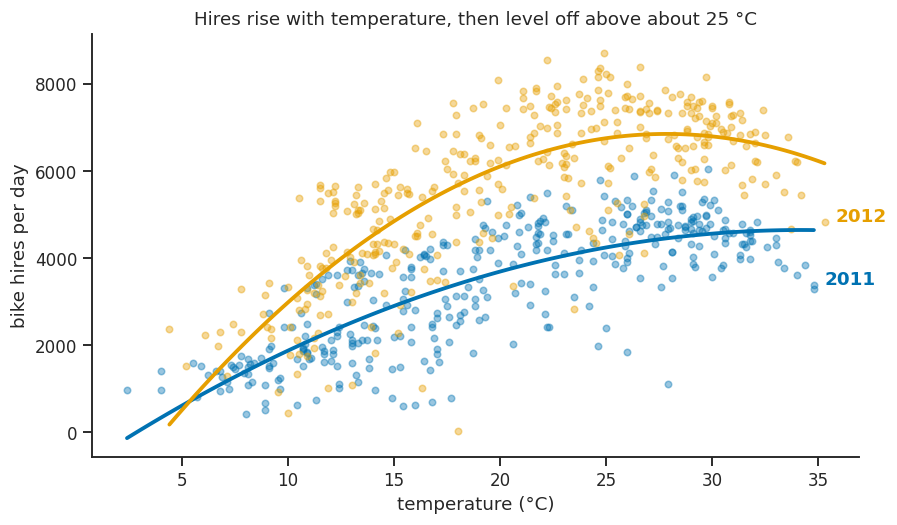

correlation between temperature and hires: 0.63


In [12]:
# 🟢 A scatter plot coloured by year, with a smooth curve fitted for each year
fig, ax = plt.subplots(figsize=(9, 5))
for i, year in enumerate([2011, 2012]):
    subset = bikes[bikes["year"] == year]                   # the rows for one year
    sns.regplot(data=subset, x="temp_c", y="total",
                order=2,                                    # fit a curve (a quadratic) instead of a straight line
                ci=None,                                    # no confidence band, to keep the chart readable
                scatter_kws={"alpha": 0.4, "s": 18},        # points: partly transparent, size 18
                line_kws={"linewidth": 2.5},                # the fitted curve: thicker
                color=OKABE_ITO[i],
                ax=ax)
    hottest = subset.loc[subset["temp_c"].idxmax()]          # the hottest day of that year
    ax.text(hottest["temp_c"] + 0.5, hottest["total"], str(year),   # label the year beside it
            color=OKABE_ITO[i], fontweight="bold")

ax.set(title="Hires rise with temperature, then level off above about 25 °C",
       xlabel="temperature (°C)", ylabel="bike hires per day")
plt.show()

print("correlation between temperature and hires:", round(bikes["temp_c"].corr(bikes["total"]), 2))

**How the code works.** [`sns.regplot`](https://seaborn.pydata.org/generated/seaborn.regplot.html) draws a scatter plot and a fitted line. With `order=2` the fitted line is a **quadratic curve**, which can bend, rather than a straight line. `scatter_kws` and `line_kws` are dictionaries of settings passed on to the points and to the line. [`.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html) computes the **Pearson correlation**, a number from −1 to +1 that measures how closely the points follow a straight line.

**Best-practice principles applied**

* **Position on two common scales** is the most accurate way to show the relationship between two numeric variables (lecture: encoding channels, ranked by accuracy).
* **Transparency** (`alpha=0.4`) addresses overplotting: where many points overlap, the colour becomes darker.
* **Direct labels** name the two years at the ends of their clouds, instead of a legend.
* **A fitted curve shows the shape of the relationship**, which a correlation coefficient on its own would hide (lecture: Anscombe's quartet). The title states the finding, including its shape.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Daily hires rise strongly with temperature, from about 1,000 to 2,000 on the coldest days to about 5,000 to 7,000 on warm days, and then flatten, or fall slightly, on the hottest days. The whole curve is higher in 2012 than in 2011. |
| **Evidence** (what shows it) | The scatter plot and its fitted curves; a correlation of about 0.63. |
| **Limits** (what could make it wrong, or narrower) | Temperature and season vary together, so this chart cannot separate the effect of warmth from that of longer days or summer holidays (step 5 looks at seasons). The quadratic curve is a description, not a model. The slight fall on the hottest days rests on few points. A correlation does not show that one variable causes the other. |

#### Chart 4.2: correlations between the numeric variables

**Questions this chart can answer**

* Which weather variables vary with daily hires, and in which direction?
* Are any two variables so closely related that they are nearly duplicates?

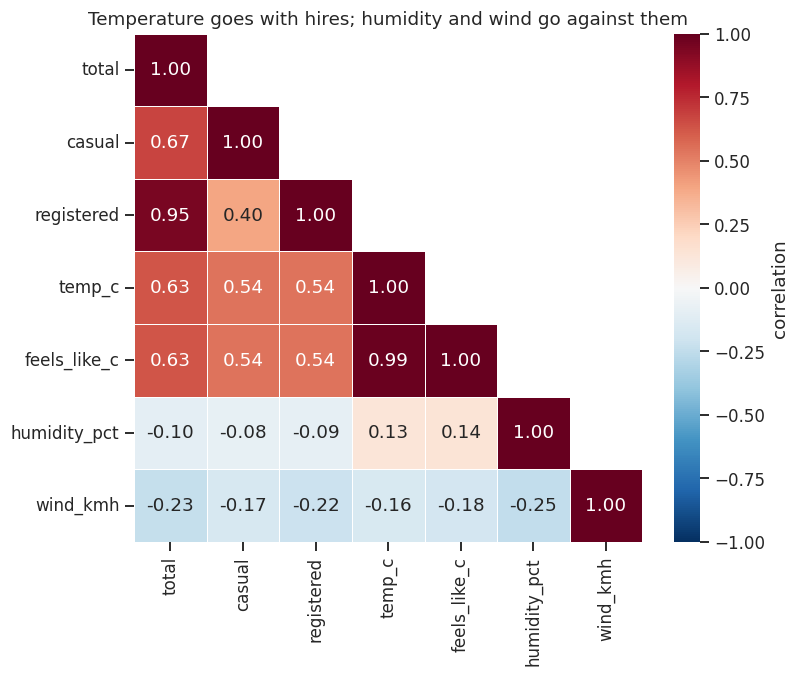

In [13]:
# 🟢 A correlation matrix, drawn as a heatmap with a diverging colour scale
columns = ["total", "casual", "registered", "temp_c", "feels_like_c", "humidity_pct", "wind_kmh"]
corr = bikes[columns].corr()                               # a 7 x 7 table of correlations

# A mask hides the upper triangle, which repeats the lower one
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)        # True above the diagonal

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr,
            mask=mask,                                     # do not draw the cells where the mask is True
            annot=True, fmt=".2f",                         # write each value, to two decimal places
            cmap="RdBu_r",                                 # diverging: blue (negative) to red (positive)
            vmin=-1, vmax=1, center=0,                     # the full range of a correlation; white at zero
            square=True,
            linewidths=0.5,                                # thin white lines between the cells
            cbar_kws={"label": "correlation"},             # the label of the colour bar
            ax=ax)
ax.set_title("Temperature goes with hires; humidity and wind go against them")
plt.show()

**How the code works.** `corr()` computes the correlation of every pair of columns. [`np.triu`](https://numpy.org/doc/stable/reference/generated/numpy.triu.html) keeps the upper triangle of a matrix; applied to a matrix of `True` values with `k=1`, it marks every cell **above** the diagonal, and [`sns.heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html) leaves those cells blank. `cbar_kws` passes settings to the colour bar.

**Best-practice principles applied**

* **A diverging colour scale centred on zero**, because a correlation has a meaningful midpoint, and fixed limits of −1 and 1, so a colour always means the same value (lecture: three kinds of colour scale).
* **The repeated upper triangle is hidden**, which halves the amount of ink without losing any information (lecture: data-ink).
* **Values are written in the cells:** the colours give the overview and the numbers the detail, so the chart still works in greyscale and for colour-blind readers (lecture: accessibility by design).

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Temperature and 'feels like' temperature are positively correlated with hires (about +0.6). Humidity and wind are weakly negatively correlated with them. The two temperature columns are almost the same variable (a correlation of about 0.99). |
| **Evidence** (what shows it) | The values in the heatmap. |
| **Limits** (what could make it wrong, or narrower) | A correlation measures only straight-line association, and Chart 4.1 showed that the temperature relationship is curved. Using both temperature columns in a later model would count the same information twice. Casual and registered hires are parts of the total, so their correlations with it are partly built in. |

### Step 5: groups and subgroups

This step splits the data by a categorical variable and compares the groups. It also checks whether a pattern seen in the whole dataset holds **within** each group: a pattern in the total can disappear, or even reverse, inside the groups (lecture: Simpson's paradox).

#### Chart 5.1: hires by season and by weather

**Questions this chart can answer**

* Which seasons have the most hires?
* How much does bad weather reduce hires, and how precise is that comparison?

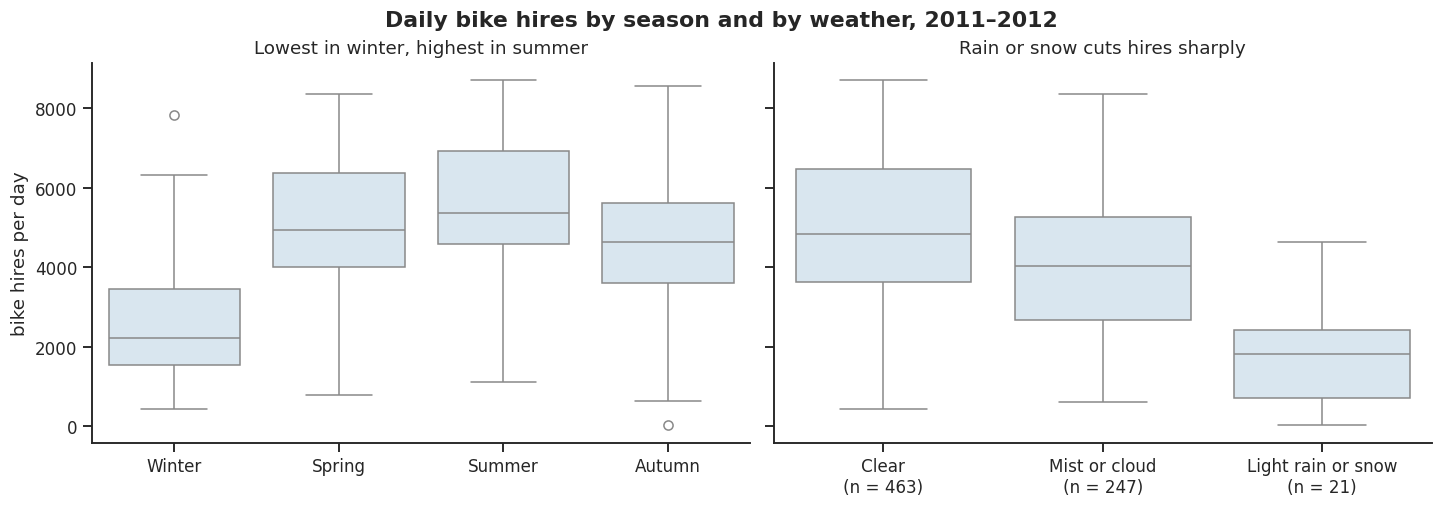

season
Winter    2209.0
Spring    4941.5
Summer    5353.5
Autumn    4634.5
Name: total, dtype: float64
weather
Clear                 4844.0
Mist or cloud         4040.0
Light rain or snow    1817.0
Name: total, dtype: float64


In [14]:
# 🟢 Two box plots side by side: daily hires by season, and by weather
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5),
                        sharey=True,                   # the same y-axis range in both plots
                        layout="constrained")

sns.boxplot(data=bikes, x="season", y="total", color="#D6E6F2", ax=axs[0])
axs[0].set(title="Lowest in winter, highest in summer", xlabel="", ylabel="bike hires per day")

# Drop the weather category that never occurs, so it does not leave an empty space
present = bikes["weather"].cat.remove_unused_categories()
sns.boxplot(data=bikes.assign(weather=present), x="weather", y="total", color="#D6E6F2", ax=axs[1])

# Add each group's number of days to its axis label
counts = present.value_counts(sort=False)
axs[1].set_xticks(range(len(counts)))
axs[1].set_xticklabels([f"{name}\n(n = {n})" for name, n in counts.items()])   # \n starts a new line
axs[1].set(title="Rain or snow cuts hires sharply", xlabel="")

fig.suptitle("Daily bike hires by season and by weather, 2011–2012", fontweight="bold")
plt.show()

print(bikes.groupby("season", observed=True)["total"].median())
print(bikes.groupby("weather", observed=True)["total"].median())

**How the code works.** [`sns.boxplot`](https://seaborn.pydata.org/generated/seaborn.boxplot.html) draws one box per category: the box spans the middle half of the days, the line inside it is the median, and points beyond the whiskers are unusual days. `.cat.remove_unused_categories()` removes the 'heavy rain or snow' category, which has no days. `bikes.assign(weather=present)` makes a temporary copy of the DataFrame with that column replaced. The list comprehension builds labels such as `Clear (n = 463)`. In `groupby`, `observed=True` reports only categories that actually occur.

**Best-practice principles applied**

* **Box plots compare whole distributions across groups**, not only their means: the lecture's chart for 'how do groups differ in distribution?'.
* **A shared y-axis** (`sharey=True`) puts the two plots on the same scale, so they can be compared directly.
* **Sample sizes are shown** under each weather group (Appendix B: sample sizes are visible when groups are compared).
* **One pale colour for every box:** the groups are already named on the axis, so a colour per box would add nothing (colour only where it carries meaning).

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Hires are lowest in winter (median about 2,200 a day) and highest in summer. Days with light rain or snow have far fewer hires (median about 1,800) than clear days (median about 4,800). |
| **Evidence** (what shows it) | The box plots, and the printed medians. |
| **Limits** (what could make it wrong, or narrower) | Only 21 days had rain or snow, so that comparison is less precise. Season and temperature overlap, so these charts cannot separate them. Each box combines two years of a growing scheme, in which 2012 was higher than 2011 in every season. |

#### Chart 5.2: two kinds of user, two patterns

**Questions this chart can answer**

* Do casual and registered users ride on the same kinds of day?
* Does a pattern in the total hide different patterns in its parts (lecture: aggregation can hide subgroups)?

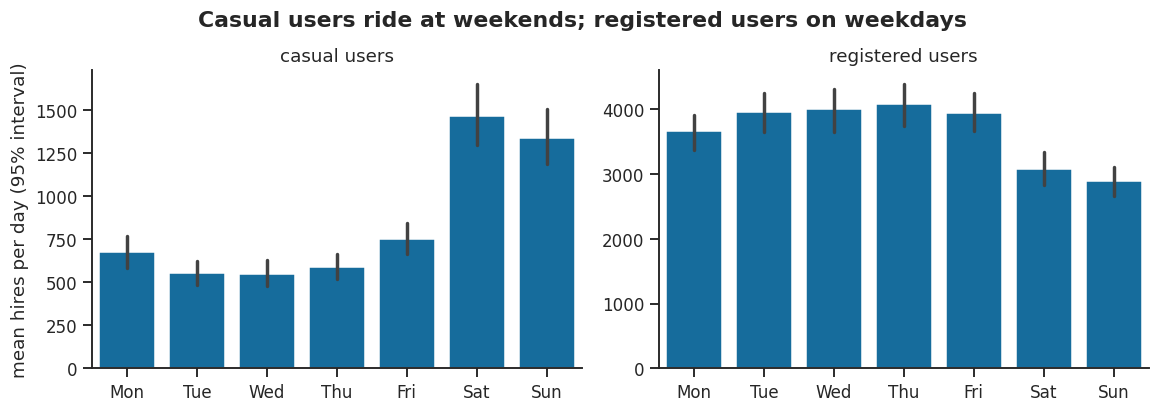

            casual  registered
workingday                    
False       1371.0      2959.0
True         607.0      3978.0


In [15]:
# 🟢 Mean daily hires by day of the week, separately for casual and registered users

# Reshape to long format: one row per day and user type, with the hires in one column
long = bikes.melt(id_vars="weekday",                     # the column to keep as it is
                  value_vars=["casual", "registered"],   # the columns to stack into one
                  var_name="user",                       # the new column holding "casual" or "registered"
                  value_name="hires")                    # the new column holding the numbers

g = sns.catplot(data=long, x="weekday", y="hires",
                col="user",                              # one plot per user type
                kind="bar",                              # bars showing the mean
                errorbar=("ci", 95),                     # with 95% confidence intervals
                color=OKABE_ITO[0],
                height=3.8, aspect=1.4,                  # each plot 3.8 inches high, 1.4 times as wide
                sharey=False)                            # each plot chooses its own y-axis range (see below)
g.set_titles("{col_name} users")                         # "casual users", "registered users"
g.set_axis_labels("", "mean hires per day (95% interval)")
g.figure.suptitle("Casual users ride at weekends; registered users on weekdays", y=1.04, fontweight="bold")
plt.show()

print(bikes.groupby("workingday")[["casual", "registered"]].mean().round(0))

**How the code works.** [`melt`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.melt.html) reshapes the data to **long format**, stacking the `casual` and `registered` columns into one column of hires with a second column saying which user type each row is; seaborn needs this to draw one plot per user type. [`sns.catplot`](https://seaborn.pydata.org/generated/seaborn.catplot.html) is a **figure-level** function: with `col="user"` it draws one plot per user type, and `kind="bar"` makes each a bar chart of means with confidence intervals.

**Best-practice principles applied**

* **Small multiples by user type**, with the **days in their natural order** (an ordered category), because the comparison of interest is the **shape** of the week.
* **Separate y-axis ranges** (`sharey=False`): registered users are several times more numerous, so on a shared scale the casual pattern would be flattened and invisible. This departs from the usual rule of shared scales, deliberately, and it is disclosed here and in the panel titles (Appendix B: scales and axes).
* **95% confidence intervals** on each bar show how precisely each mean is estimated (Appendix B: uncertainty).
* **The title states the finding**, which is the contrast between the two plots.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Casual hires roughly double at weekends (about 1,400 a day on non-working days, against about 600 on working days), while registered hires are higher on working days. The scheme serves two different uses: leisure and commuting. |
| **Evidence** (what shows it) | The two plots, and the printed means for working and non-working days. |
| **Limits** (what could make it wrong, or narrower) | The total hides this contrast, because the two weekly patterns partly cancel each other out. 'Casual' and 'registered' are the operator's categories: the data do not record the purpose of each trip. Because the two plots have different y-axis ranges, compare their shapes, not the heights of their bars. |

### Step 6: time structure

A variable recorded over time can contain a **trend** (a long-run rise or fall), a **seasonal cycle** (a pattern that repeats every year, week or day), sudden **changes**, and **gaps**. A useful first chart shows the raw series faintly and a smoothed version on top.

#### Chart 6.1: daily hires over two years

**Questions this chart can answer**

* Is there a trend, a seasonal cycle, or both?
* Are there sudden changes or gaps?

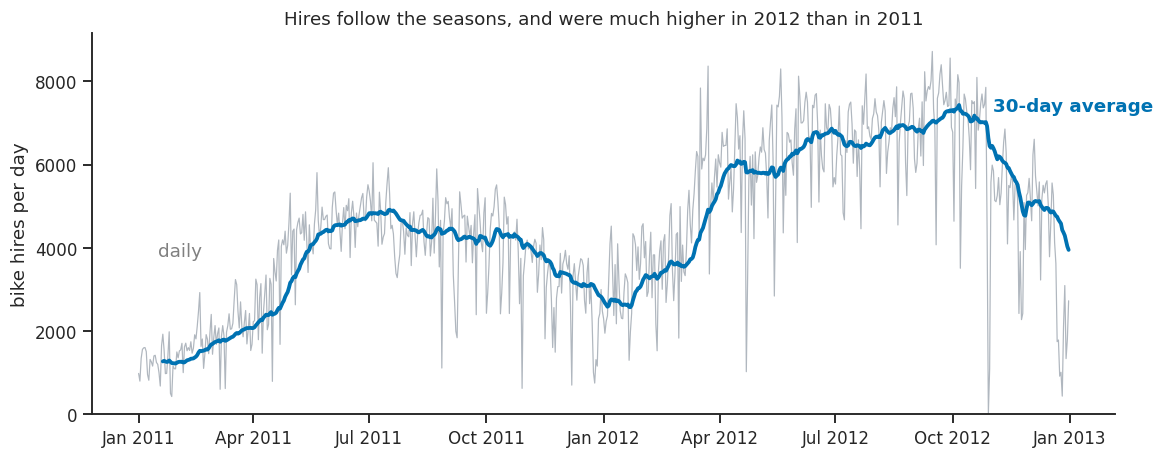

year
2011    3406.0
2012    5600.0
Name: total, dtype: float64


In [16]:
# 🟢 Daily hires (faint), with a 30-day moving average on top
series = bikes.set_index("date")["total"]                 # a Series indexed by date
smooth = series.rolling("30D", min_periods=20).mean()     # the mean of each 30-day window

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(series.index, series.values, color=GREY, linewidth=0.8)        # the raw daily values
ax.plot(smooth.index, smooth.values, color=OKABE_ITO[0], linewidth=2.5) # the moving average
ax.text(smooth.index[-60], smooth.iloc[-60] + 900, "30-day average", color=OKABE_ITO[0], fontweight="bold")
ax.text(series.index[15], series.iloc[15] + 2600, "daily", color="grey")

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))  # a tick every January, April, July, October
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))             # labels such as "Jan 2011"
ax.set(title="Hires follow the seasons, and were much higher in 2012 than in 2011",
       xlabel="", ylabel="bike hires per day",
       ylim=(0, None))                                     # start the y-axis at zero; None keeps the top automatic
plt.show()

print(bikes.groupby("year")["total"].mean().round(0))

**How the code works.** [`.rolling("30D")`](https://pandas.pydata.org/docs/reference/api/pandas.Series.rolling.html) creates a **moving window** of 30 days ending on each date, and `.mean()` takes the average within each window: a **moving average**, which smooths out the day-to-day variation. `min_periods=20` requires at least 20 days in a window, so the first weeks are left blank rather than averaged over too few days. [`MonthLocator`](https://matplotlib.org/stable/api/dates_api.html#matplotlib.dates.MonthLocator) and [`DateFormatter`](https://matplotlib.org/stable/api/dates_api.html#matplotlib.dates.DateFormatter) control where the date ticks go and how they are written.

**Best-practice principles applied**

* **A line chart** for change over time (lecture: choosing a chart from the question). **The raw series is faint and the smoothed series bold**, so the trend stands out while the daily variation remains visible (lecture: pre-attentive attributes, one strong colour for the main point).
* **A wide aspect ratio**, so the slopes are not exaggerated (lecture: aspect ratio, banking to 45°).
* **The y-axis starts at zero**, so the size of the seasonal swing is not exaggerated; **direct labels** replace a legend; **date ticks** every three months are readable without crowding.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Hires follow a strong seasonal cycle, low in winter and high from late spring to early autumn, and the whole level rose between the two years: the mean was about 3,400 hires a day in 2011 and about 5,600 in 2012. |
| **Evidence** (what shows it) | The time series, its moving average, and the printed yearly means. |
| **Limits** (what could make it wrong, or narrower) | Two years cannot distinguish a lasting trend from one unusual year. The growth probably reflects the scheme expanding (more stations and more members), which the dataset does not record. A 30-day average smooths away short events, including the anomaly examined in step 7. |

#### Chart 6.2: the same months, compared across the two years

**Questions this chart can answer**

* Is the seasonal shape the same in both years?
* In which months was the growth largest?

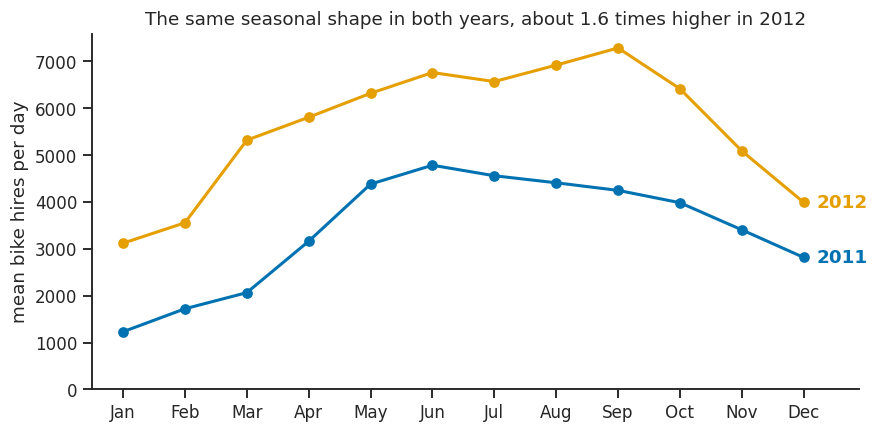

In [17]:
# 🟢 Mean daily hires in each month, one line per year, on a common month axis
monthly = bikes.groupby(["year", "month"])["total"].mean().reset_index()   # one row per year and month

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, year in enumerate([2011, 2012]):
    data = monthly[monthly["year"] == year]
    ax.plot(data["month"], data["total"],
            marker="o",                                 # a circle at each month's value
            color=OKABE_ITO[i], linewidth=2)
    ax.text(12.2, data["total"].iloc[-1], str(year),    # label the line just right of December
            color=OKABE_ITO[i], va="center", fontweight="bold")

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.set_xticks(range(1, 13), month_names)               # ticks at 1 to 12, labelled with month names
ax.set(title="The same seasonal shape in both years, about 1.6 times higher in 2012",
       xlabel="", ylabel="mean bike hires per day",
       ylim=(0, None), xlim=(0.5, 12.9))               # extra room on the right for the labels
plt.show()

**How the code works.** `groupby(["year", "month"])` groups the days by both year and month, and `.mean()` takes the mean daily hires in each of the 24 groups; `.reset_index()` turns the two group labels back into ordinary columns. `ax.set_xticks(positions, labels)` places a tick at each month number and writes its name.

**Best-practice principles applied**

* **A common month axis** for both years, so the comparison is one position against another, the most accurate encoding (lecture: encoding channels, ranked).
* **Only two colours**, from a colour-blind-safe palette, with **direct labels**; markers show that each value is a monthly mean, not a continuous measurement.
* **The y-axis starts at zero**, so the ratio between the two years is read correctly.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | Both years have the same seasonal shape, with a peak from early summer to early autumn, but 2012 is higher in every month, by roughly 60% on average. |
| **Evidence** (what shows it) | The two lines, and the vertical distance between them in each month. |
| **Limits** (what could make it wrong, or narrower) | Monthly means hide day-to-day variation and differences in the number of days per month. The cause of the growth is not in the data. |

### Step 7: outliers and anomalies

An **outlier** is a value far from the others; an **anomaly** is a value that does not fit what is expected. The lecture sorts them into three kinds: **impossible** (an error: correct it or set it to missing), **implausible in context** (check it against the source), and **genuinely extreme** (real, so keep it). The decision for each needs evidence, often from outside the dataset.

#### Chart 7.1: the unusual days, examined

**Questions this chart can answer**

* Which days are far from what their season and year would lead us to expect?
* Is each one an error, a real but unusual event, or both?

In [18]:
# 🟢 The five days with the fewest hires, and the day recorded with 0% humidity
print("The five days with the fewest hires:")
lowest = bikes.nsmallest(5, "total")                        # the 5 rows with the smallest totals
print(lowest[["date", "weekday", "season", "weather", "temp_c", "total"]].to_string(index=False))
print()
print("The day recorded with 0% humidity:")
dry = bikes.loc[bikes["humidity_pct"] == 0, ["date", "weather", "temp_c", "humidity_pct", "total"]]
print(dry.to_string(index=False))                           # index=False: do not print the row numbers

The five days with the fewest hires:
      date weekday season            weather  temp_c  total
2012-10-29     Mon Autumn Light rain or snow    18.0     22
2011-01-27     Thu Winter              Clear     8.0    431
2012-12-26     Wed Winter Light rain or snow    10.0    441
2011-01-26     Wed Winter Light rain or snow     8.9    506
2011-03-06     Sun Winter      Mist or cloud    15.4    605

The day recorded with 0% humidity:
      date            weather  temp_c  humidity_pct  total
2011-03-10 Light rain or snow    16.0           0.0    623


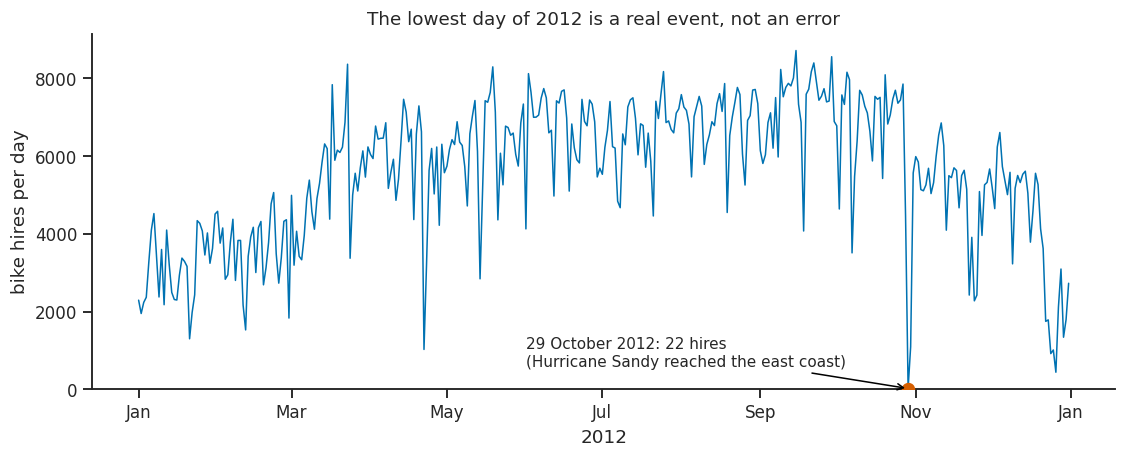

In [19]:
# 🟢 The 2012 series, with its lowest day highlighted and explained
y2012 = bikes[bikes["year"] == 2012].set_index("date")["total"]
low_day = y2012.idxmin()                                    # the date of the lowest value

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(y2012.index, y2012.values, color=OKABE_ITO[0], linewidth=1)
ax.scatter([low_day], [y2012[low_day]], color=OKABE_ITO[5], s=60, zorder=3)   # zorder=3: draw on top of the line
ax.annotate(f"{low_day:%d %B %Y}: {y2012[low_day]:,} hires\n(Hurricane Sandy reached the east coast)",
            xy=(low_day, y2012[low_day]),                   # the point the arrow points to
            xytext=(pd.Timestamp("2012-06-01"), 600),       # where the text is placed
            arrowprops={"arrowstyle": "->", "color": "black"},
            fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))    # month names only, since the year is fixed
ax.set(title="The lowest day of 2012 is a real event, not an error",
       xlabel="2012", ylabel="bike hires per day", ylim=(0, None))
plt.show()

**How the code works.** [`nsmallest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nsmallest.html) returns the rows with the smallest values of a column. `idxmin()` returns the date of the lowest value. [`ax.annotate`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.annotate.html) draws the text and an arrow to the point; `f"{low_day:%d %B %Y}"` formats the date as, for example, '29 October 2012'.

**Best-practice principles applied**

* **The anomaly is explained on the chart itself**, with its date, its value and its cause (Appendix B: key events are annotated on the figure).
* **One highlight colour** for the single point being discussed; everything else stays in the base colour (lecture: pre-attentive attributes).
* **The context is kept:** the whole year is shown, so the reader can see how far the day falls below its neighbours.

**Insight**

| | |
|---|---|
| **Claim** (what we found) | The lowest day in the dataset, 29 October 2012, had only 22 hires: Hurricane Sandy reached the US east coast that day, and the scheme suspended its service. It is a **genuinely extreme** observation, not an error. By contrast, the day recorded with **0% humidity** (10 March 2011) is almost certainly a **recording error**. |
| **Evidence** (what shows it) | The printed lists, the annotated chart, and public records of the storm, which are not part of the dataset. |
| **Limits** (what could make it wrong, or narrower) | The explanation relies on knowledge from outside the dataset, which a report should cite. The other low days in the printout are winter days or rain and snow days: real effects of the weather, which should also be kept. Each decision belongs in the decision log (step 8). |

### Step 8: data quality, revisited

The charts revealed things that the first round of cleaning could not have known. They are now recorded in a **decision log** (Week 4), and the data are updated accordingly. In a full project, you would then add these steps to the preprocessing cell and run the protocol again: exploration and cleaning alternate.

In [20]:
# 🟢 Act on what the EDA found, and record each decision with its reason
decisions = pd.DataFrame([
    {"found": "humidity of 0% on 2011-03-10 (1 day)",
     "decision": "set to missing",
     "reason": "physically implausible: a recording error"},
    {"found": "22 hires on 2012-10-29 (Hurricane Sandy)",
     "decision": "keep, and flag",
     "reason": "a real event: removing it would hide the effect of extreme weather"},
    {"found": "temp_c and feels_like_c correlate at about 0.99",
     "decision": "use temp_c only in later analysis",
     "reason": "near-duplicate variables would count the same information twice"},
    {"found": "only 21 days with rain or snow",
     "decision": "report the sample size with every comparison",
     "reason": "small groups give imprecise estimates"},
])

bikes.loc[bikes["humidity_pct"] == 0, "humidity_pct"] = np.nan          # set the impossible value to missing
bikes["extreme_event"] = bikes["date"] == pd.Timestamp("2012-10-29")    # a True/False flag for the storm day

print("humidity values now missing:", bikes["humidity_pct"].isna().sum(),
      "| days flagged as extreme events:", bikes["extreme_event"].sum())
decisions

humidity values now missing: 1 | days flagged as extreme events: 1


,found,decision,reason
0,humidity of 0% on 2011-03-10 (1 day),set to missing,physically implausible: a recording error
1,22 hires on 2012-10-29 (Hurricane Sandy),"keep, and flag",a real event: removing it would hide the effec...
2,temp_c and feels_like_c correlate at about 0.99,use temp_c only in later analysis,near-duplicate variables would count the same ...
3,only 21 days with rain or snow,report the sample size with every comparison,small groups give imprecise estimates


**What you should see:** one humidity value now missing, one day flagged, and a decision log with four rows, each stating what was found, what was decided and why. This is the Week 4 decision log, now filled in **as a result of** the EDA.

`bikes.loc[condition, column] = value` changes the value of `column` in every row where `condition` is true.

---
## 4. Summary of insights

| # | Claim | Evidence | Limits |
|---|---|---|---|
| 1 | Daily hires vary from under 1,000 to over 8,000, around a typical 4,500. | Chart 2.1 | The days mix seasons and two years of growth. |
| 2 | Warmer days have many more hires, levelling off above about 25 °C. | Chart 4.1; a correlation of about 0.63 | Temperature and season overlap; the relationship is not shown to be causal. |
| 3 | Rain or snow cuts hires to well under half of a clear day's. | Chart 5.1 | Based on only 21 rain or snow days. |
| 4 | Casual users ride at weekends; registered users on weekdays. | Chart 5.2 | The user types are the operator's categories; trip purpose is not recorded. |
| 5 | A strong seasonal cycle, and about 60% more hires in 2012 than in 2011. | Charts 6.1 and 6.2 | Two years only; the scheme's expansion is not recorded in the data. |
| 6 | The lowest day (22 hires) was the day of Hurricane Sandy; one humidity value is an error. | Chart 7.1 | The explanation relies on sources outside the dataset. |

**Questions for confirmation or modelling.** Exploration suggests hypotheses; it does not confirm them (lecture: three different jobs). Two that follow from this analysis:

1. Does temperature still affect hires after taking season and year into account?
2. Is the registered users' weekday pattern explained by commuting hours? The hourly file, `hour.csv`, could show this.

---
## 5. Exercise: repeat the process on the UCI Air Quality dataset

Now apply the same process, on your own, to a different dataset. Work in the cells below, and add as many code and Markdown cells as you need.

### The dataset

Hourly readings from a device of chemical sensors placed at road level in a city in Italy, from March 2004 to April 2005: concentrations of carbon monoxide (CO), benzene (C6H6), nitrogen oxides (NOx and NO2) and other gases, together with temperature (T), relative humidity (RH) and absolute humidity (AH).

* **Source:** UCI Machine Learning Repository, dataset 360: [archive.ics.uci.edu/dataset/360/air+quality](https://archive.ics.uci.edu/dataset/360/air+quality)
* **Zip file:** `https://archive.ics.uci.edu/static/public/360/air+quality.zip`, which contains `AirQualityUCI.csv`
* **Licence:** CC BY 4.0. **Citation:** De Vito, S. et al. (2008), "On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario", *Sensors and Actuators B: Chemical*, 129(2), 750–757.

### What the documentation tells you, which your preprocessing must handle

* The file uses **semicolons** (`;`) to separate columns and **commas** as the decimal mark, as is common in Italy: read it with `pd.read_csv(..., sep=";", decimal=",")` ([`read_csv` parameters](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)).
* **Missing values are recorded as −200**, a disguised missing value (Week 4).
* The date and the time are in two separate columns, `Date` (in the form DD/MM/YYYY) and `Time` (HH.MM.SS), which you should combine into one datetime with an explicit `format=`.
* The file ends with **two empty columns** and some **empty rows**.
* The column names contain the instrument names: for example, `CO(GT)` is the true CO concentration from a reference analyser, in mg/m³, and `C6H6(GT)` is benzene, in µg/m³.

### Your tasks

1. **Load the data and record their provenance**, as in section 1.
2. **Preprocess in one cell**, with a comment explaining each step and why, ending with validation checks that fail loudly, as in section 2.
3. **Work through the eight-step protocol**, with at least **one chart per step** (here, step 3 needs a real missingness chart). For **each chart**, write in a Markdown cell: the questions it can answer; the best-practice principles it applies; and the insight, as a claim, its evidence and its limits.
4. **Write a summary table of your insights**, and **two questions** for confirmation or modelling.
5. **Fill in a decision log** for every change the EDA led you to make.

### Hints

* A missingness chart **by variable** and another **over time** are both informative here.
* The time structure includes a **daily cycle** (look at the hour of the day) as well as a seasonal one; compare weekdays with weekends.
* One variable is missing far more often than the others: decide what to do with it, and justify your decision in the log.

In [21]:
# Task 1: load the data and record their provenance

In [22]:
# Task 2: preprocessing in one cell

In [23]:
# Task 3: the EDA protocol. Add a code cell for each chart, followed by a Markdown cell
# with its questions, the principles applied, and its claim, evidence and limits.

✍️ *After each chart, add a Markdown cell like this one for its questions, the principles it applies, and its claim, evidence and limits.*

---
### References and further reading

* Fanaee-T, H. and Gama, J. (2014), "Event labeling combining ensemble detectors and background knowledge", *Progress in Artificial Intelligence*, 2(2), 113–127.
* De Vito, S. et al. (2008), "On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario", *Sensors and Actuators B: Chemical*, 129(2), 750–757.
* Anscombe, F. J. (1973), "Graphs in statistical analysis", *The American Statistician*, 27(1), 17–21.
* Cleveland, W. S. and McGill, R. (1984), "Graphical perception", *Journal of the American Statistical Association*, 79(387), 531–554.
* Tukey, J. W. (1977), *Exploratory Data Analysis*, Addison-Wesley.
* pandas: [Time series and date functionality](https://pandas.pydata.org/docs/user_guide/timeseries.html); [Reshaping and pivot tables (melt)](https://pandas.pydata.org/docs/user_guide/reshaping.html); [Categorical data](https://pandas.pydata.org/docs/user_guide/categorical.html).
* seaborn: [Visualising distributions](https://seaborn.pydata.org/tutorial/distributions.html); [Visualising statistical relationships](https://seaborn.pydata.org/tutorial/relational.html); [Visualising categorical data](https://seaborn.pydata.org/tutorial/categorical.html).
* The Week 7 lecture.